In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # add mini2p-analysis/ to the path
from cell_explorer import CellExplorer
from receptive_field import RFAnalyzer

EBR = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251211_LDR_LDR004_ltdk_11.pkl"
ce = CellExplorer(EBR)
ana = RFAnalyzer(ce, ego_radius=0.4)            # reuse the CellExplorer you already loaded
figure_dir = r"G:\My Drive\Conferences\iNav-26\poster\figure-6"

%load_ext autoreload
%autoreload 2

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


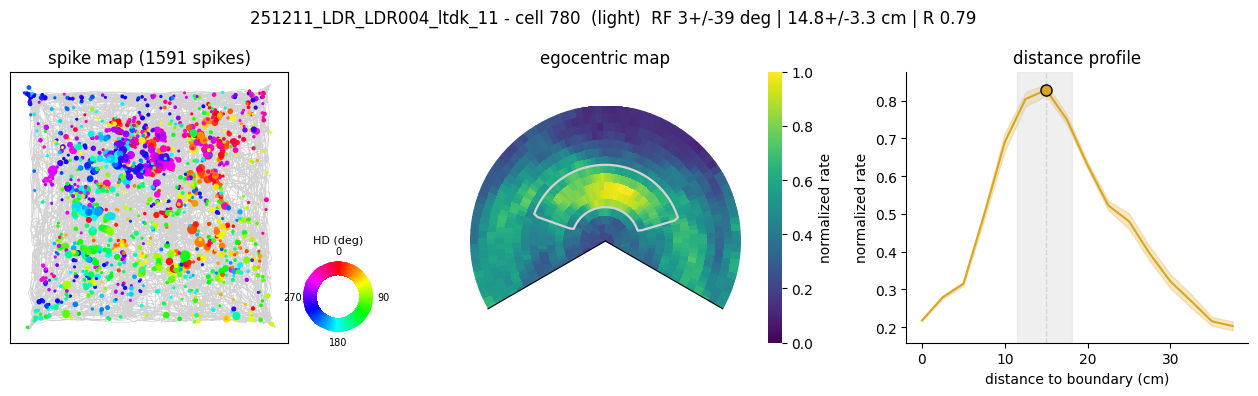

In [64]:
# any RFAnalyzer knob(s), one row each:
import matplotlib.pyplot as plt
fig = ana.plot_cell_figure(780, condition="light")

import os
figure_name = os.path.join(figure_dir, '6B-2.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg', dpi=300)

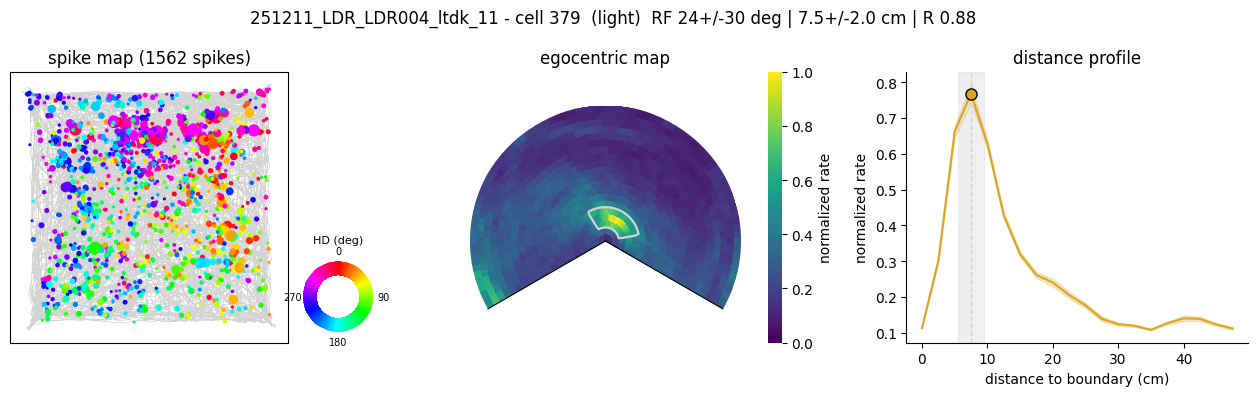

In [40]:
fig = ana.plot_cell_figure(379, condition="light")

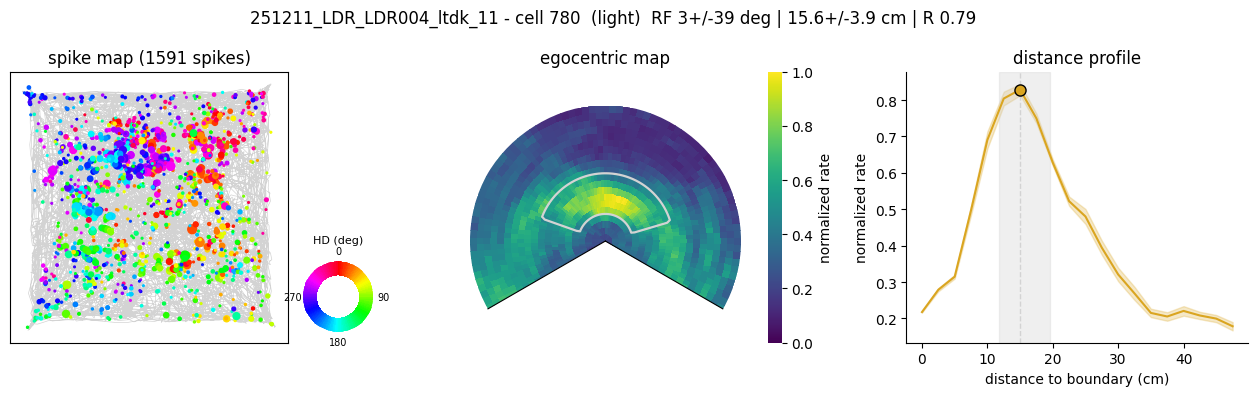

In [49]:
fig = ana.plot_cell_figure(780, condition="light")

  DMM065 (reference): rot=0.0 scale=1.00 dx=0 dy=0 r=1.000 n_cells=9387
  LDR004: rot=7.0 scale=1.10 dx=13 dy=-43 r=0.691 n_cells=11704

Aligned 2 animals to 'DMM065' (work frame 400x400).


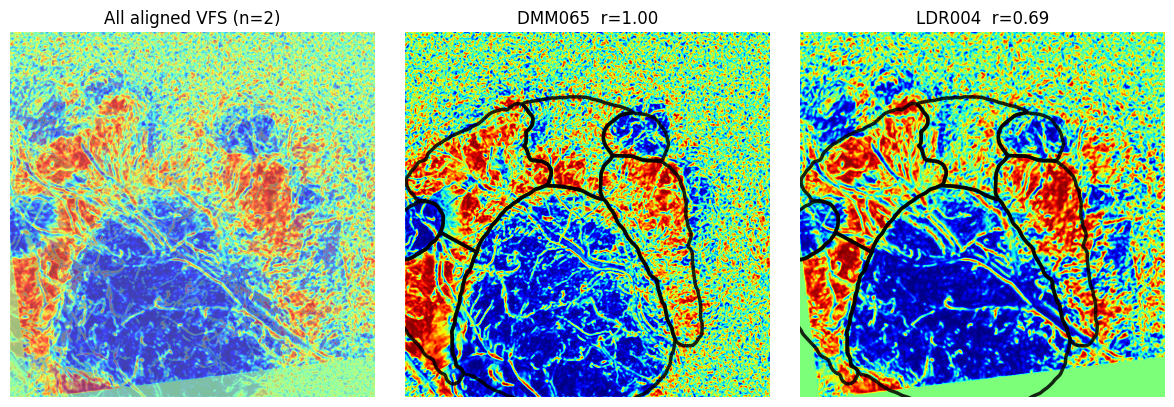

In [66]:
# === pooled VISUAL density across DMM065 + LDR004 (white bg, area-framed) ==
import importlib, widefield_viz, widefield_align
import pandas as pd
importlib.reload(widefield_viz); importlib.reload(widefield_align)

MINI2P = r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis"
if MINI2P not in sys.path:
    sys.path.insert(0, MINI2P)
import widefield_viz, widefield_align
importlib.reload(widefield_viz); importlib.reload(widefield_align)   # <-- picks up the new view mode
from widefield_align import MultiAnimalAligner, DATA_ROOT

animals = ["DMM065", "LDR004"]
all_df = pd.concat(
    [pd.read_pickle(os.path.join(DATA_ROOT, a, f"{a}_sessions_visual.pkl")).assign(animal=a)
     for a in animals],
    ignore_index=True)

aligner = MultiAnimalAligner(all_df)
aligner.align(reference="DMM065")
aligner.plot_alignment()                       # QC: confirm Pearson r before trusting the pool

pooled = aligner.make_pooled_plotter()          # white bg + area-boundary frame, by default

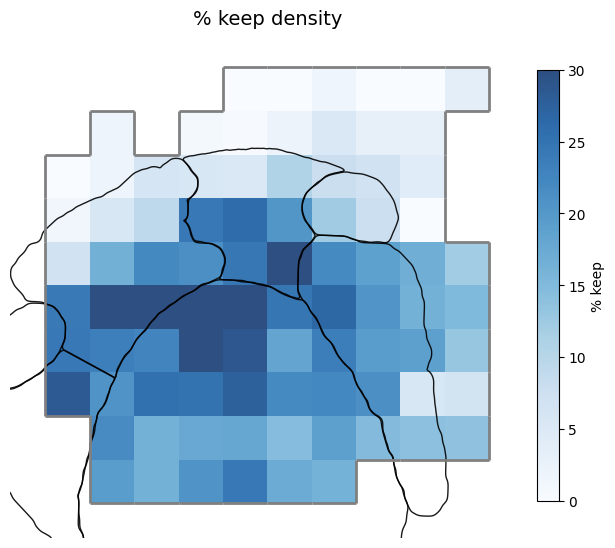

In [69]:
# any RFAnalyzer knob(s), one row each:
import matplotlib.pyplot as plt
fig, axes = pooled.plot_cell_density(cmap='Blues', frame=False, label_areas=False, zoom=True, vmin=0, vmax=30, n_bins=10, min_count=20)

import os
figure_name = os.path.join(figure_dir, '6C.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg', dpi=300)

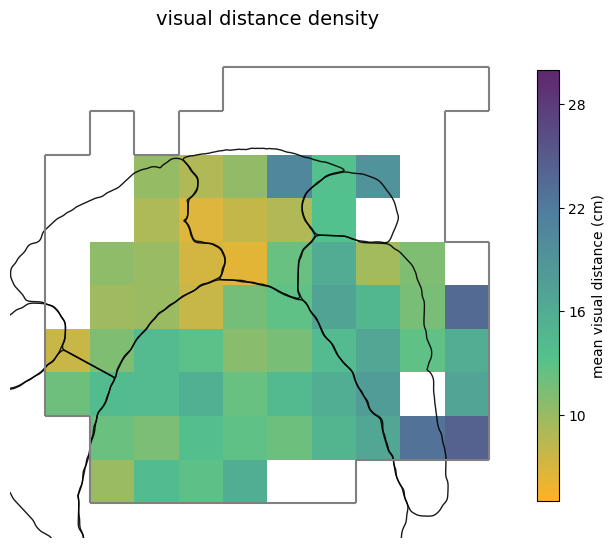

In [83]:
# any RFAnalyzer knob(s), one row each:
import matplotlib.pyplot as plt
fig, axes = pooled.plot_cell_density(feature="distance", frame=False, label_areas=False, zoom=True, vmin=5, vmax=30, n_bins=10, min_count=20, boundary_lw=1.5)

import os
figure_name = os.path.join(figure_dir, '6D.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg', dpi=300)

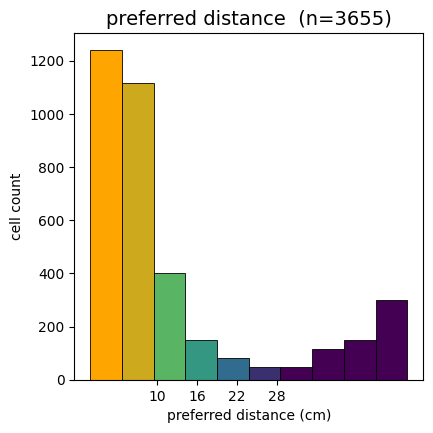

In [74]:
# any RFAnalyzer knob(s), one row each:
import matplotlib.pyplot as plt
fig, axes = pooled.plot_distance_histogram(n_bins=10, vmin=5, vmax = 30)

import os
figure_name = os.path.join(figure_dir, '6E.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg', dpi=300)